# EDA beer4rec

Проверяем три вещи: качество исходных отзывов, разреженность истории и покрытие
временной валидации. Результаты нужны для выбора правил очистки и честного
сравнения ALS с неперсональными бейзлайнами.

In [2]:
import csv
import hashlib
import statistics
from collections import Counter
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

CSV_PATH = Path("data/raw/beer_reviews.csv")
if not CSV_PATH.is_file():
    CSV_PATH = Path("..") / CSV_PATH  # запуск из notebooks/
if not CSV_PATH.is_file():
    raise FileNotFoundError("Распакуйте beer_reviews.csv в data/raw/ по инструкции в README.")

SCORES = ("overall", "aroma", "appearance", "palate", "taste")
MIN_HISTORY = 10
POSITIVE = 4.0

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
TEAL, BLUE, GREY = "#187A78", "#336CAB", "#A7B7CB"


def number(value):
    return f"{value:,}".replace(",", " ")


def show_table(headers, rows):
    def line(row):
        return "| " + " | ".join(map(str, row)) + " |"

    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)), *map(line, rows)])))


def timestamp_text(value):
    return datetime.fromtimestamp(value, UTC).isoformat(sep=" ")


with CSV_PATH.open("rb") as source:
    print("SHA-256:", hashlib.file_digest(source, "sha256").hexdigest())

SHA-256: 951e688265643b7265d62f0b522f45aae80b10cfdba4016972231a0adb9afe26


## 1. Состав, качество и очистка

Единица исходных данных — отзыв с пятью оценками, временем, профилем и ID сорта.
Проверяем обязательные поля и метаданные, затем оставляем одну запись на пару
«пользователь — сорт»: самый ранний валидный отзыв. При совпадении времени
оставляем первую строку CSV. Данные читаем построчно; профили заменяем внутренними
ID и не выводим в результатах.

In [3]:
def to_float(value: str) -> float:
    try:
        return float(value)
    except ValueError:
        return float("nan")


missing = Counter()
raw_users, raw_items, breweries, styles = set(), set(), set(), set()
times, removed = Counter(), Counter()
item_meta, non_missing_abv, conflicts = {}, {}, set()
rows = 0
users: dict[str, int] = {}
pairs: dict[tuple[int, int], tuple[int, float]] = {}
with CSV_PATH.open(encoding="utf-8-sig", newline="") as source:
    reader = csv.reader(source)
    fields = next(reader)
    ix = {name: i for i, name in enumerate(fields)}
    rating_columns = [ix[f"review_{name}"] for name in SCORES]
    for row in reader:
        rows += 1
        if len(row) != len(fields):
            raise ValueError(f"Unexpected number of columns at CSV line {reader.line_num}")
        for field, value in zip(fields, row, strict=True):
            if not value.strip():
                missing[field] += 1
        user = row[ix["review_profilename"]].strip()
        beer = int(row[ix["beer_beerid"]])
        brewery = int(row[ix["brewery_id"]])
        style = row[ix["beer_style"]]
        timestamp = int(row[ix["review_time"]])
        ratings = [to_float(row[i]) for i in rating_columns]
        overall = ratings[0]
        times[timestamp] += 1
        if user:
            raw_users.add(user)
        raw_items.add(beer)
        breweries.add(brewery)
        styles.add(style)

        meta = (row[ix["beer_name"]], style, brewery)
        if item_meta.setdefault(beer, meta) != meta:
            conflicts.add(beer)
        abv = to_float(row[ix["beer_abv"]])
        if 0 <= abv <= 100 and non_missing_abv.setdefault(beer, abv) != abv:
            conflicts.add(beer)

        if not user:
            removed["missing_user"] += 1
            continue
        if not all(0 < value <= 5 for value in ratings):
            removed["invalid_scores"] += 1
            continue

        pair = (users.setdefault(user, len(users)), beer)
        previous = pairs.get(pair)
        if previous is not None:
            removed["repeat_pair"] += 1
        # If the earliest timestamp is tied, keep the first valid row in this CSV.
        if previous is None or timestamp < previous[0]:
            pairs[pair] = (timestamp, overall)


assert rows - removed.total() == len(pairs)

show_table(
    ("Показатель", "Значение"),
    [
        ("Отзывов до очистки", number(rows)),
        ("Профилей / сортов", f"{number(len(raw_users))} / {number(len(raw_items))}"),
        (
            "Пивоварен / стилей / полей",
            f"{len(breweries):,} / {len(styles)} / {len(fields)}",
        ),
        (
            "Пропуски по полям",
            ", ".join(f"`{f}`: {number(n)}" for f, n in sorted(missing.items())),
        ),
        (
            "Без профиля / с недопустимой оценкой",
            f"{removed['missing_user']} / {removed['invalid_scores']}",
        ),
        ("Лишних записей повторных пар", number(removed["repeat_pair"])),
        ("Пар после очистки", number(len(pairs))),
        ("Сортов после очистки", number(len({item_id for _, item_id in pairs}))),
        ("Сорты без известной крепости", number(len(raw_items) - len(non_missing_abv))),
        (
            "Диапазон известной крепости",
            f"{min(non_missing_abv.values())}–{max(non_missing_abv.values())}%",
        ),
        ("Сорты с конфликтом метаданных", len(conflicts)),
    ],
)

| Показатель | Значение |
| --- | --- |
| Отзывов до очистки | 1 586 614 |
| Профилей / сортов | 33 387 / 66 055 |
| Пивоварен / стилей / полей | 5,840 / 104 / 13 |
| Пропуски по полям | `beer_abv`: 67 785, `brewery_name`: 15, `review_profilename`: 348 |
| Без профиля / с недопустимой оценкой | 348 / 7 |
| Лишних записей повторных пар | 14 786 |
| Пар после очистки | 1 571 473 |
| Сортов после очистки | 66 051 |
| Сорты без известной крепости | 17 043 |
| Диапазон известной крепости | 0.01–57.7% |
| Сорты с конфликтом метаданных | 0 |

**Вывод.** Удалено 348 строк без профиля, 7 с недопустимой оценкой и 14 786 повторов.
После очистки осталось 1 571 473 пары. Крепость неизвестна у 17 043 сортов (25,8%):
сохраняем их в каталоге, исключаем только при фильтре по крепости. Метаданные
и крепость для офлайн-каталога берём из train.

## 2. Время и разреженность

Проверяем, как отзывы распределены по годам, насколько длинные истории у
пользователей и какая доля отзывов приходится на самые популярные сорта.

| Показатель | Значение |
| --- | --- |
| Период, UTC | 1996-08-22 00:00:01+00:00 — 2012-01-11 12:35:48+00:00 |
| Медиана отзывов на пользователя / сорт | 3 / 2 |
| Заполненность матрицы | 0.071% |
| Доля отзывов у 1% популярных сортов | 37.7% |

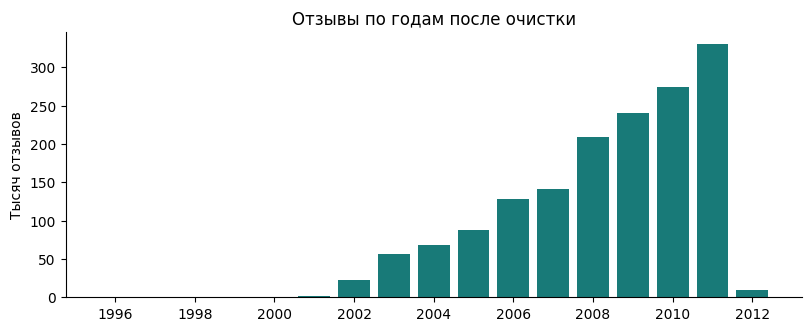

In [4]:
from math import ceil

clean_times = Counter(timestamp for timestamp, _ in pairs.values())
years = Counter()
for timestamp, count in clean_times.items():
    years[datetime.fromtimestamp(timestamp, UTC).year] += count
user_counts = Counter(user for user, _ in pairs)
item_counts = Counter(item for _, item in pairs)
top_item_count = ceil(len(item_counts) * 0.01)
top_share = sum(n for _, n in item_counts.most_common(top_item_count)) / len(pairs)
density = len(pairs) / (len(user_counts) * len(item_counts))

show_table(
    ("Показатель", "Значение"),
    [
        ("Период, UTC", f"{timestamp_text(min(times))} — {timestamp_text(max(times))}"),
        (
            "Медиана отзывов на пользователя / сорт",
            f"{statistics.median(user_counts.values()):g} / {statistics.median(item_counts.values()):g}",
        ),
        ("Заполненность матрицы", f"{density:.3%}"),
        ("Доля отзывов у 1% популярных сортов", f"{top_share:.1%}"),
    ],
)

fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
year_axis = sorted(years)
ax.bar(year_axis, [years[year] / 1000 for year in year_axis], color=TEAL)
ax.set(title="Отзывы по годам после очистки", ylabel="Тысяч отзывов")
ax.set_xticks(range(1996, 2013, 2))
plt.show()

**Вывод.** В 1996 году одна запись, 2012 покрыт только до 11 января. Делим по
времени и числу событий, чтобы сохранить хронологию. Медиана истории — 3 сорта,
у сорта — 2 отзыва; заполнено 0,071% матрицы. На 1% популярных сортов приходится
37,7% отзывов. Это обосновывает сглаживание TopRated и разбор результатов
по длине истории и популярности сорта.

## 3. Временное разбиение, оценки и длина истории

Глобально делим очищенные пары по `review_time` примерно 80/10/10. Записи с
одинаковым временем на границе уходят в более позднее окно. Каталог и история
фиксируются по train и остаются одинаковыми для validation и test.

| Train | Значение |
| --- | --- |
| Отзывов / сортов | 1 257 178 / 54 908 |
| Пользователей | 27 572 |
| Пользователей с ≥10 отзывами | 8 789 (31.9%) |
| Доля оценок ≥4 | 63.0% |

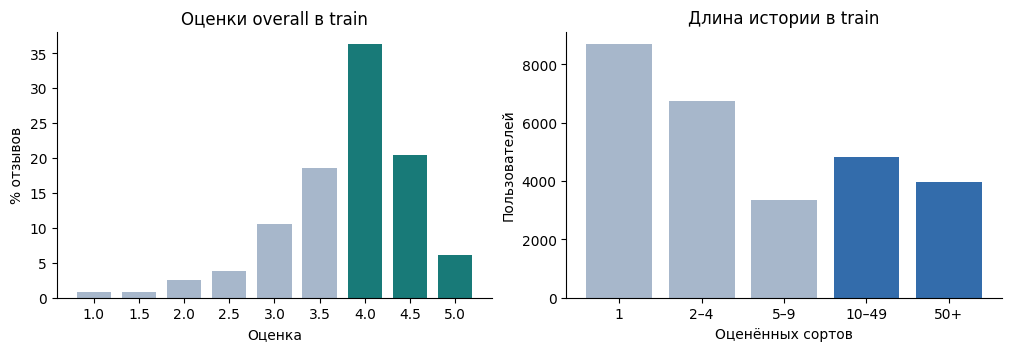

In [5]:
def quantile_boundary(time_counts: Counter[int], target: int) -> int:
    """Timestamp of the row at zero-based rank target; ties go to the later window."""
    cumulative = 0
    for timestamp, count in sorted(time_counts.items()):
        cumulative += count
        if cumulative > target:
            return timestamp
    raise ValueError("Cannot compute the split boundary")


total = len(pairs)
val_from = quantile_boundary(clean_times, total * 8 // 10)
test_from = quantile_boundary(clean_times, total * 9 // 10)
assert val_from < test_from

train_users, train_items, train_scores = Counter(), Counter(), Counter()
for (user, item), (timestamp, score) in pairs.items():
    if timestamp < val_from:
        train_users[user] += 1
        train_items[item] += 1
        train_scores[score] += 1

train_rows = train_users.total()
positive_share = sum(n for score, n in train_scores.items() if score >= POSITIVE) / train_rows
sufficient_history = sum(n >= MIN_HISTORY for n in train_users.values())

show_table(
    ("Train", "Значение"),
    [
        ("Отзывов / сортов", f"{number(train_rows)} / {number(len(train_items))}"),
        ("Пользователей", number(len(train_users))),
        (
            "Пользователей с ≥10 отзывами",
            f"{number(sufficient_history)} ({sufficient_history / len(train_users):.1%})",
        ),
        ("Доля оценок ≥4", f"{positive_share:.1%}"),
    ],
)

fig, (scores_ax, hist_ax) = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
scores = sorted(train_scores)
scores_ax.bar(
    scores,
    [100 * train_scores[score] / train_rows for score in scores],
    width=0.38,
    color=[TEAL if score >= POSITIVE else GREY for score in scores],
)
scores_ax.set(title="Оценки overall в train", ylabel="% отзывов", xlabel="Оценка")
scores_ax.set_xticks(scores)
buckets = (
    ("1", 1, 1),
    ("2–4", 2, 4),
    ("5–9", 5, 9),
    ("10–49", 10, 49),
    ("50+", 50, float("inf")),
)
hist_ax.bar(
    [label for label, _, _ in buckets],
    [sum(lo <= n <= hi for n in train_users.values()) for _, lo, hi in buckets],
    color=[GREY] * 3 + [BLUE] * 2,
)
hist_ax.set(title="Длина истории в train", xlabel="Оценённых сортов", ylabel="Пользователей")
plt.show()

**Вывод.** В train 63,0% отзывов с `overall >= 4`. Это доля среди написанных
отзывов: релевантность неоценённых сортов неизвестна. Только 31,9% пользователей
train имеют историю из ≥10 сортов, поэтому для остальных планируем неперсональный
список.

## 4. Кто попадёт в офлайн-оценку

Ранжируем весь train-каталог, исключая уже оценённые пользователем сорта.
Отложенная оценка ≥4 считается известным позитивом, если сорт есть в каталоге.
В оценку входят пользователи с ≥10 train-отзывами и хотя бы одним таким позитивом.
По каждой отложенной положительной оценке считаем первую применимую причину
исключения, чтобы причины не пересекались.

| Окно | Начало (UTC) | Отзывов | Пользователей | В оценке | Позитивы: все → в оценке |
| --- | --- | --- | --- | --- | --- |
| validation | 2011-01-27 04:01:10+00:00 | 157 147 | 7 967 | 2 961 (37.2%) | 98 945 → 62 675 |
| test | 2011-07-17 01:05:30+00:00 | 157 148 | 7 469 | 2 376 (31.8%) | 96 880 → 43 473 |

| Категория позитива | Validation | Test |
| --- | --- | --- |
| Сорт вне train | 12 604 (12.7%) | 21 995 (22.7%) |
| Нет истории | 15 499 (15.7%) | 25 455 (26.3%) |
| История < 10 | 8 167 (8.3%) | 5 957 (6.1%) |
| В оценке | 62 675 (63.3%) | 43 473 (44.9%) |

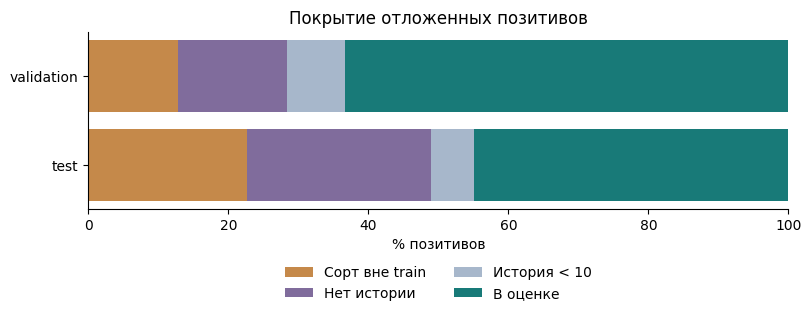

In [6]:
window_users = {"validation": set(), "test": set()}
window_rows, window_positives = Counter(), Counter()
eligible = {"validation": set(), "test": set()}
cohorts = {period: Counter() for period in eligible}
for (u, i), (ts, score) in pairs.items():
    if ts < val_from:
        continue
    period = "validation" if ts < test_from else "test"
    window_rows[period] += 1
    window_users[period].add(u)
    if score < POSITIVE:
        continue
    window_positives[period] += 1
    if i not in train_items:
        group = "cold_item"
    elif u not in train_users:
        group = "cold_user"
    elif train_users[u] < MIN_HISTORY:
        group = "short_history"
    else:
        group = "eligible"
        eligible[period].add(u)
    cohorts[period][group] += 1


periods = ("validation", "test")
starts = {"validation": val_from, "test": test_from}
assert train_rows + window_rows.total() == total
assert all(cohorts[p].total() == window_positives[p] for p in periods)
show_table(
    (
        "Окно",
        "Начало (UTC)",
        "Отзывов",
        "Пользователей",
        "В оценке",
        "Позитивы: все → в оценке",
    ),
    [
        (
            p,
            timestamp_text(starts[p]),
            number(window_rows[p]),
            number(len(window_users[p])),
            f"{number(len(eligible[p]))} ({len(eligible[p]) / len(window_users[p]):.1%})",
            f"{number(window_positives[p])} → {number(cohorts[p]['eligible'])}",
        )
        for p in periods
    ],
)

groups = {
    "cold_item": ("Сорт вне train", "#C5894A"),
    "cold_user": ("Нет истории", "#806C9C"),
    "short_history": ("История < 10", GREY),
    "eligible": ("В оценке", TEAL),
}
show_table(
    ("Категория позитива", "Validation", "Test"),
    [
        (
            label,
            *[
                f"{number(cohorts[p][group])} ({cohorts[p][group] / window_positives[p]:.1%})"
                for p in periods
            ],
        )
        for group, (label, _) in groups.items()
    ],
)

fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
left = [0.0, 0.0]
for group, (label, color) in groups.items():
    shares = [100 * cohorts[p][group] / window_positives[p] for p in periods]
    ax.barh(periods, shares, left=left, label=label, color=color)
    left = [x + y for x, y in zip(left, shares, strict=True)]
ax.invert_yaxis()
ax.set(title="Покрытие отложенных позитивов", xlabel="% позитивов", xlim=(0, 100))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
plt.show()

**Вывод.** В validation попадают 2 961 пользователь и 62 675 известных позитивов;
в test — **2 376 пользователей и 43 473 позитива (44,9%)**. Результат сравнения
будет относиться к этой когорте и каталогу из 54 908 train-сортов. Покрытие ниже
на более далёком test: больше сортов и пользователей вне train.

## Решения для дизайн-документа

- Сохраняем разбиение примерно 80/10/10 и оцениваем ранжирование каталога по
  NDCG@10 и Recall@10. Границы и параметры протокола фиксируем; варианты моделей
  и гиперпараметры выбираем только по validation.
- Персонализируем от 10 оценённых сортов; для остальных пользователей используем
  неперсональный список. Сорта без ABV исключаем только при запросе фильтра по крепости.
- Будущие оценки ≥4 — наблюдаемые позитивы, а не полный список предпочтений. В CSV
  нет показов, кликов и текущего ассортимента. Рост продуктовой метрики этим
  экспериментом не измеряем.

См. [дизайн-документ, §2.3](../docs/ml_system_design_doc.md#23-этапы-решения-задачи).